# Quarterback efficiency

Key metrics, all on **dropbacks** (passes, sacks and scrambles):

| Metric | Meaning |
|---|---|
| `epa_per_db` | EPA per dropback: overall production |
| `cpoe` | Completion % over expected, given throw depth, coverage, etc.: accuracy |
| `success_rate` | Share of dropbacks with positive EPA: consistency |
| `sack_rate` | Sacks per dropback |
| `composite` | Average of the EPA and CPOE z-scores among qualified QBs |

In [1]:
import sys
sys.path.insert(0, "../src")

import pandas as pd
from nfl_analytics import load_pbp, offensive_plays
pd.set_option("display.precision", 3)

SEASON = 2025  # change to 2026 for the current season to date

In [2]:
from nfl_analytics import qb_stats

plays = offensive_plays(load_pbp(SEASON))
qbs = qb_stats(plays, min_dropbacks=270)  # ~15 per game over 18 weeks
qbs

,name,team,dropbacks,epa_per_db,total_epa,success_rate,cpoe,pass_tds,ints,sacks,sack_rate,composite
player_id,,,,,,,,,,,,
00-0039851,D.Maye,NE,488,0.334,163.016,0.561,10.334,24.0,7.0,35.0,0.072,2.391
00-0036264,J.Love,GB,433,0.317,137.477,0.527,6.615,21.0,5.0,17.0,0.039,1.759
00-0026498,M.Stafford,LA,514,0.247,127.036,0.527,1.448,32.0,8.0,19.0,0.037,0.679
00-0033077,D.Prescott,DAL,516,0.227,117.218,0.490,1.743,24.0,4.0,21.0,0.041,0.638
00-0033106,J.Goff,DET,473,0.146,69.089,0.482,2.830,23.0,6.0,28.0,0.059,0.458
00-0034869,S.Darnold,SEA,391,0.135,52.971,0.524,5.952,18.0,10.0,22.0,0.056,0.885
00-0035710,D.Jones,IND,343,0.134,45.839,0.481,0.408,14.0,6.0,20.0,0.058,0.039
00-0039918,C.Williams,CHI,526,0.133,70.046,0.460,-3.117,23.0,7.0,15.0,0.029,-0.496
00-0039732,B.Nix,DEN,555,0.128,70.813,0.449,-0.445,20.0,9.0,17.0,0.031,-0.115


## Ranked by composite (EPA + CPOE)

In [3]:
qbs.sort_values("composite", ascending=False)[["name", "team", "dropbacks", "epa_per_db", "cpoe", "composite"]].head(10)

,name,team,dropbacks,epa_per_db,cpoe,composite
player_id,,,,,,
00-0039851,D.Maye,NE,488,0.334,10.334,2.391
00-0036264,J.Love,GB,433,0.317,6.615,1.759
00-0034869,S.Darnold,SEA,391,0.135,5.952,0.885
00-0026498,M.Stafford,LA,514,0.247,1.448,0.679
00-0033077,D.Prescott,DAL,516,0.227,1.743,0.638
00-0033106,J.Goff,DET,473,0.146,2.830,0.458
00-0040743,T.Shough,NO,271,0.093,4.068,0.420
00-0036389,J.Hurts,PHI,443,0.085,4.203,0.407
00-0036212,T.Tagovailoa,MIA,308,0.063,4.643,0.378


## Accuracy vs. production

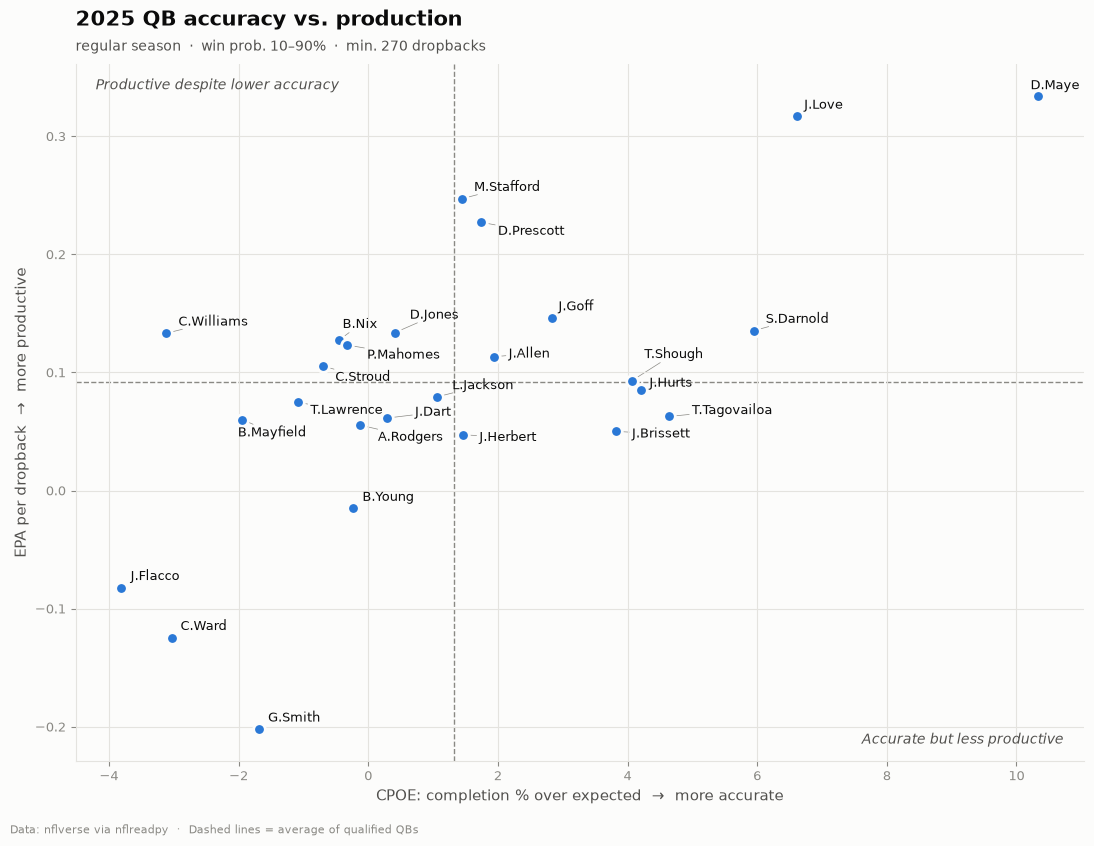

In [4]:
from nfl_analytics import plot_epa_vs_cpoe, plot_epa_ranking

subtitle = "regular season  ·  win prob. 10–90%  ·  min. 270 dropbacks"
fig, ax = plot_epa_vs_cpoe(qbs, title=f"{SEASON} QB accuracy vs. production", subtitle=subtitle)

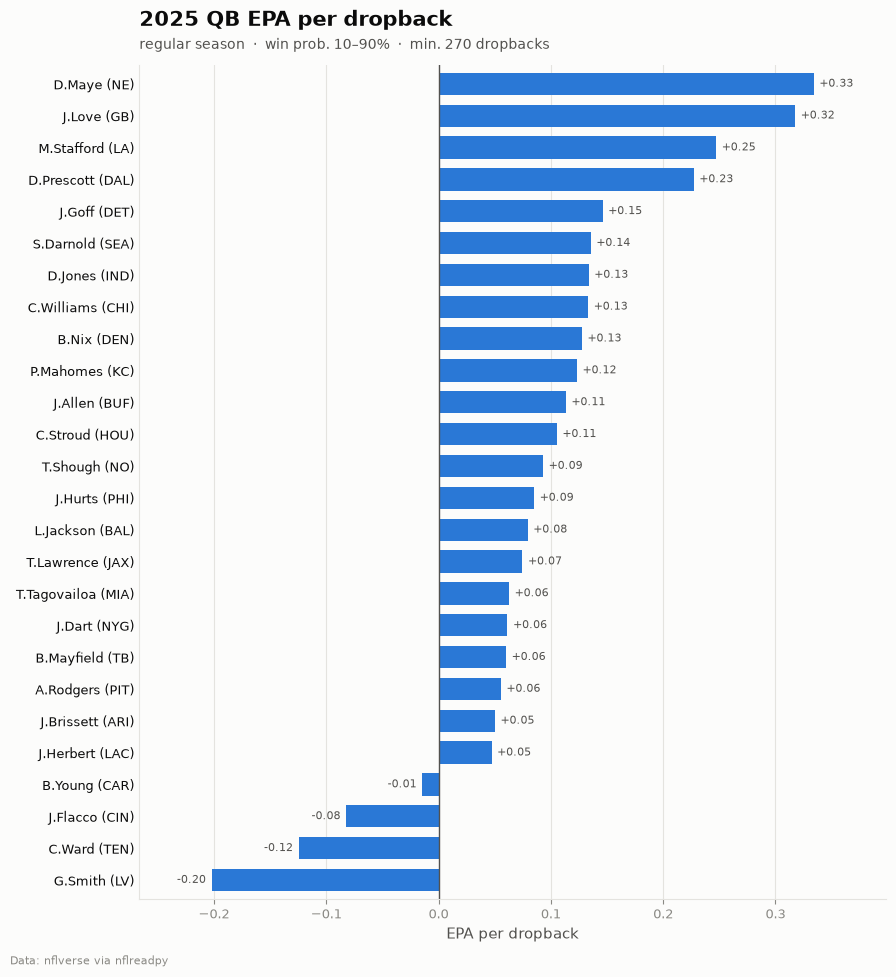

In [5]:
fig, ax = plot_epa_ranking(qbs, title=f"{SEASON} QB EPA per dropback", subtitle=subtitle)

## Ideas to explore next
- **Stability:** load two seasons and correlate each QB's EPA and CPOE year over year. Which metric holds up?
- **Situational splits:** 3rd down, red zone, under pressure (`was_pressure`), play-action.
- **Air yards vs. YAC:** `air_epa` vs. `yac_epa` shows who creates value downfield.
- **Weekly trend:** rolling EPA/dropback by week for one QB.